In [6]:
import sys

print("Python version:", sys.version)
print("Runtime connected successfully!")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Runtime connected successfully!


# Understanding Human Visual Attention Through Gaze Trajectories in Natural Images

## 1. Project Overview

This project investigates how people visually explore natural photographs using eye-tracking data from the COCO-FreeView dataset.

The study focuses on understanding where participants direct their visual attention, how fixation locations are distributed across images, and how visual attention patterns vary between participants.

## 2. Research Question

How do people distribute their visual attention when freely viewing natural photographs?

## 3. Research Objectives

1. Analyse where participants look first when viewing an image.
2. Identify regions that receive the highest number of visual fixations.
3. Compare fixation patterns across participants to understand similarities and differences.

## 4. Dataset

The project uses the publicly available COCO-FreeView dataset. It contains eye-tracking recordings collected while participants freely viewed natural images without a specific visual search target.

## 5. Methodology

The analysis will use Python to load, inspect, process and visualise fixation data. Statistical summaries and visualisations will be used to investigate the research objectives.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os

project_path = "/content/drive/MyDrive/COCO-FreeView-Research"

folders = ["Dataset", "Figures", "Results"]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

print(os.listdir(project_path))

Project folders created successfully!
['Dataset', 'Figures', 'Results']


## 6. Dataset Source and Availability

**Dataset:** COCO-FreeView

**Official source:** https://sites.google.com/view/cocosearch/coco-freeview

**Dataset paper:** Chen et al. (2022), *Characterizing Target-Absent Human Attention*, CVPR Workshops.

The publicly available eye-fixation data includes training and validation sets. The testing data has been taken down by the dataset maintainers.

This project will use the publicly available fixation data for exploratory analysis.

## 7. Understanding the Dataset Structure

The COCO-FreeView fixation data is stored in JSON format.

Each record represents a participant viewing an image during a free-viewing trial.

### Important variables

- `trial_ind`: Image presentation index.
- `name`: Image filename.
- `subject`: Participant identifier.
- `task`: Target category associated with the image in COCO-Search18.
- `condition`: Target-present or target-absent condition.
- `X`: Horizontal coordinates of fixations.
- `Y`: Vertical coordinates of fixations.
- `T`: Duration of each fixation.
- `length`: Total number of fixations.
- `split`: Dataset partition (train, valid or test).

### Important considerations

1. The X, Y and T arrays represent corresponding fixation observations.
2. The initial centre fixation is included in the fixation sequence.
3. Image dimensions are 1680 × 1050 pixels.
4. The dataset contains observations from 10 university students.

### Planned analysis

The project will investigate:
1. Initial gaze behaviour.
2. Spatial distribution of fixations.
3. Similarities and differences in gaze patterns across participants.

In [11]:
!pip install remotezip

In [12]:
from remotezip import RemoteZip
import os

url = "https://ailb-web.ing.unimore.it/publicfiles/ScanDiff_ICCV2025/coco_freeview.zip"

dataset_folder = os.path.join(project_path, "Dataset")

wanted_files = [
    "COCOFreeView_fixations_train.json",
    "COCOFreeView_fixations_validation.json"
]

with RemoteZip(url) as remote_zip:
    for filename in wanted_files:
        print("Downloading:", filename)

        with remote_zip.open(filename) as source:
            destination = os.path.join(dataset_folder, filename)

            with open(destination, "wb") as target:
                while True:
                    chunk = source.read(1024 * 1024)
                    if not chunk:
                        break
                    target.write(chunk)

        print("Saved:", destination)

print("\nDownload completed!")
print(os.listdir(dataset_folder))

Downloading: COCOFreeView_fixations_train.json
Saved: /content/drive/MyDrive/COCO-FreeView-Research/Dataset/COCOFreeView_fixations_train.json
Downloading: COCOFreeView_fixations_validation.json
Saved: /content/drive/MyDrive/COCO-FreeView-Research/Dataset/COCOFreeView_fixations_validation.json

Download completed!
['COCOFreeView_fixations_train.json', 'COCOFreeView_fixations_validation.json']


## 9. Dataset Acquisition

The COCO-FreeView fixation data was obtained from a third-party research archive hosted by the Artificial Intelligence and Biomedical Imaging Lab (AILB), University of Modena and Reggio Emilia.

The following files were downloaded:

- `COCOFreeView_fixations_train.json`
- `COCOFreeView_fixations_validation.json`

The original official download endpoint was inaccessible during project preparation. The downloaded files will be checked against the official COCO-FreeView README and published dataset description before analysis.

The testing file is not included in the current analysis.

In [13]:
import json
import os

train_path = os.path.join(
    dataset_folder,
    "COCOFreeView_fixations_train.json"
)

valid_path = os.path.join(
    dataset_folder,
    "COCOFreeView_fixations_validation.json"
)

with open(train_path, "r") as f:
    train_data = json.load(f)

with open(valid_path, "r") as f:
    valid_data = json.load(f)

print("Training data type:", type(train_data))
print("Validation data type:", type(valid_data))

print("\nTraining records:", len(train_data))
print("Validation records:", len(valid_data))

print("\nFirst training record:")

if isinstance(train_data, list):
    print(train_data[0])
elif isinstance(train_data, dict):
    print(list(train_data.items())[:1])

Training data type: <class 'list'>
Validation data type: <class 'list'>

Training records: 30129
Validation records: 6457

First training record:
{'name': '000000019544.jpg', 'subject': 101, 'condition': 'freeview', 'X': [829.9, 827.3, 1451.9, 1193.3, 785.4, 500.2, 416.4, 285.1, 292.9, 656.6, 1107.6, 595.7, 648.4, 590.4, 843.9], 'Y': [523.5, 362.3, 416.5, 265.4, 334.1, 394.1, 536.1, 513.4, 494.0, 577.1, 646.9, 471.6, 435.6, 534.3, 453.8], 'T': [266.0, 226.0, 217.0, 302.0, 265.0, 204.0, 205.0, 159.0, 259.0, 197.0, 407.0, 22.0, 38.0, 236.0, 1152.0], 'length': 15, 'split': 'train', 'fixOnTarget': False, 'correct': 1}


In [14]:
# Inspect dataset structure

print("TRAINING DATA")
print("Unique subjects:", sorted(set(
    record["subject"] for record in train_data
)))

print("\nRecord keys:")
print(sorted(train_data[0].keys()))

print("\nChecking fixation array lengths:")

mismatches = 0

for record in train_data + valid_data:
    if not (
        len(record["X"]) ==
        len(record["Y"]) ==
        len(record["T"]) ==
        record["length"]
    ):
        mismatches += 1

print("Records with inconsistent lengths:", mismatches)

print("\nCoordinate ranges:")
all_x = [x for r in train_data for x in r["X"]]
all_y = [y for r in train_data for y in r["Y"]]

print("X range:", min(all_x), "to", max(all_x))
print("Y range:", min(all_y), "to", max(all_y))

print("\nFixation duration range:")
all_t = [t for r in train_data for t in r["T"]]

print(min(all_t), "to", max(all_t), "ms")

TRAINING DATA
Unique subjects: [101, 102, 103, 104, 105, 107, 108, 109, 110, 116]

Record keys:
['T', 'X', 'Y', 'condition', 'correct', 'fixOnTarget', 'length', 'name', 'split', 'subject']

Checking fixation array lengths:
Records with inconsistent lengths: 0

Coordinate ranges:
X range: 8.5 to 1679.4
Y range: 0.2 to 1049.7

Fixation duration range:
1.0 to 5269.0 ms


## 10. Initial Data Validation

The downloaded training and validation JSON files were successfully loaded into Python.

Initial validation produced the following observations:

- The training dataset contains 30,129 records.
- The validation dataset contains 6,457 records.
- Ten unique participant IDs were identified in the training data.
- No records had mismatched X, Y, T and length arrays.
- All observed fixation coordinates fall within the expected image dimensions of 1680 × 1050 pixels.
- Fixation durations range from 1 ms to 5,269 ms in the training dataset.

The initial structural checks passed. Further inspection of fixation durations and archive metadata is required before analysis.

In [15]:
# Combine both datasets
all_data = train_data + valid_data

# Collect all fixation durations
all_durations = [
    duration
    for record in all_data
    for duration in record["T"]
]

# Calculate duration statistics
print("Total records:", len(all_data))
print("Total fixation observations:", len(all_durations))

print("\nDuration statistics (milliseconds):")
print("Minimum:", np.min(all_durations))
print("Median:", np.median(all_durations))
print("Mean:", np.mean(all_durations))
print("95th percentile:", np.percentile(all_durations, 95))
print("99th percentile:", np.percentile(all_durations, 99))
print("Maximum:", np.max(all_durations))

# Investigate durations above 5000 ms
long_fixations = []

for record in all_data:
    for duration in record["T"]:
        if duration > 5000:
            long_fixations.append({
                "image": record["name"],
                "subject": record["subject"],
                "duration_ms": duration,
                "split": record["split"]
            })

print("\nFixations above 5000 ms:", len(long_fixations))
print(long_fixations[:10])

Total records: 36586
Total fixation observations: 565062

Duration statistics (milliseconds):
Minimum: 1.0
Median: 232.0
Mean: 262.2076250039819
95th percentile: 519.0
99th percentile: 853.390000000014
Maximum: 5270.0

Fixations above 5000 ms: 41
[{'image': '000000498125.jpg', 'subject': 110, 'duration_ms': 5263.0, 'split': 'train'}, {'image': '000000041398.jpg', 'subject': 104, 'duration_ms': 5262.0, 'split': 'train'}, {'image': '000000449528.jpg', 'subject': 108, 'duration_ms': 5266.0, 'split': 'train'}, {'image': '000000462054.jpg', 'subject': 110, 'duration_ms': 5259.0, 'split': 'train'}, {'image': '000000483996.jpg', 'subject': 109, 'duration_ms': 5256.0, 'split': 'train'}, {'image': '000000576956.jpg', 'subject': 101, 'duration_ms': 5260.0, 'split': 'train'}, {'image': '000000143933.jpg', 'subject': 104, 'duration_ms': 5257.0, 'split': 'train'}, {'image': '000000140122.jpg', 'subject': 109, 'duration_ms': 5260.0, 'split': 'train'}, {'image': '000000267175.jpg', 'subject': 110, 'd

In [16]:
# Compare official README schema with downloaded archive

official_keys = {
    "trial_ind", "name", "subject", "task",
    "condition", "X", "Y", "T", "length", "split"
}

archive_keys = set(train_data[0].keys())

print("Fields missing from archive:")
print(sorted(official_keys - archive_keys))

print("\nAdditional archive fields:")
print(sorted(archive_keys - official_keys))

print("\nTraining split labels:")
print(set(r["split"] for r in train_data))

print("\nValidation split labels:")
print(set(r["split"] for r in valid_data))

print("\nCondition values:")
print(set(r["condition"] for r in train_data + valid_data))

Fields missing from archive:
['task', 'trial_ind']

Additional archive fields:
['correct', 'fixOnTarget']

Training split labels:
{'train'}

Validation split labels:
{'validation'}

Condition values:
{'freeview'}


### 14. First Post-Centre Fixation

The dataset includes an initial centre fixation at index 0.
To study the first actual gaze movement after stimulus presentation,
we extract the coordinates at index 1 from each trial.

The initial centre fixation is excluded from this analysis.

In [17]:
# Extract the first post-centre fixation from each trial

records = train_data + valid_data

first_fixations = []

for record in records:
    if len(record["X"]) > 1 and len(record["Y"]) > 1:
        first_fixations.append({
            "image": record["name"],
            "subject": record["subject"],
            "split": record["split"],
            "first_x": record["X"][1],
            "first_y": record["Y"][1]
        })

first_fixations_df = pd.DataFrame(first_fixations)

print("Total trials:", len(records))
print("Extracted first fixations:", len(first_fixations_df))

display(first_fixations_df.head())

Total trials: 36586
Extracted first fixations: 36544


,image,subject,split,first_x,first_y
0,000000019544.jpg,101,train,827.3,362.3
1,000000019544.jpg,102,train,867.5,317.7
2,000000019544.jpg,103,train,790.2,342.7
3,000000019544.jpg,104,train,1018.4,580.1
4,000000019544.jpg,105,train,809.7,476.1


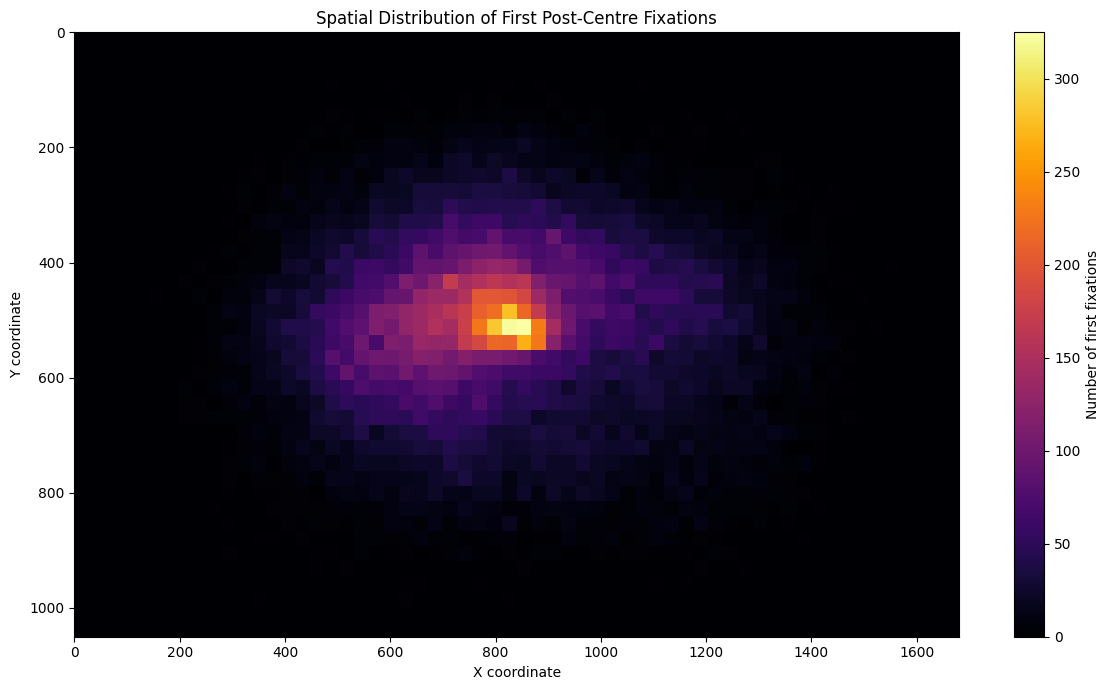

Figure saved: /content/drive/MyDrive/COCO-FreeView-Research/Figures/first_fixation_heatmap.png


In [18]:
plt.figure(figsize=(12, 7))

plt.hist2d(
    first_fixations_df["first_x"],
    first_fixations_df["first_y"],
    bins=[60, 40],
    range=[[0, 1680], [0, 1050]],
    cmap="inferno"
)

plt.colorbar(label="Number of first fixations")

plt.xlim(0, 1680)
plt.ylim(1050, 0)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Spatial Distribution of First Post-Centre Fixations")

plt.tight_layout()

figure_path = os.path.join(
    project_path, "Figures", "first_fixation_heatmap.png"
)

plt.savefig(figure_path, dpi=300)
plt.show()

print("Figure saved:", figure_path)

In [19]:
# Calculate first-fixation central tendency

image_center_x = 840
image_center_y = 525

mean_x = first_fixations_df["first_x"].mean()
mean_y = first_fixations_df["first_y"].mean()

first_fixations_df["distance_from_center"] = np.sqrt(
    (first_fixations_df["first_x"] - image_center_x)**2 +
    (first_fixations_df["first_y"] - image_center_y)**2
)

print("Image centre:", (image_center_x, image_center_y))

print("\nMean first-fixation location:")
print("X:", round(mean_x, 2))
print("Y:", round(mean_y, 2))

print("\nMean distance from image centre:")
print(round(first_fixations_df["distance_from_center"].mean(), 2), "pixels")

print("\nMedian distance from image centre:")
print(round(first_fixations_df["distance_from_center"].median(), 2), "pixels")

Image centre: (840, 525)

Mean first-fixation location:
X: 804.86
Y: 508.37

Mean distance from image centre:
227.43 pixels

Median distance from image centre:
214.13 pixels


### Findings: First-Fixation Distribution

The pooled heatmap revealed a strong concentration of first
post-centre fixations around the central region of the images.

The mean first-fixation location was (804.86, 508.37),
compared with the image centre at (840, 525).

The mean and median distances from the image centre were
227.43 pixels and 214.13 pixels, respectively.

These observations suggest a central tendency in first-fixation
locations, alongside considerable spatial variation.

In [20]:
# Compare first-fixation behaviour across participants

participant_stats = (
    first_fixations_df
    .groupby("subject")
    .agg(
        trials=("image", "count"),
        mean_x=("first_x", "mean"),
        mean_y=("first_y", "mean"),
        mean_distance=("distance_from_center", "mean"),
        median_distance=("distance_from_center", "median")
    )
    .round(2)
    .reset_index()
)

display(participant_stats)

,subject,trials,mean_x,mean_y,mean_distance,median_distance
0,101,3666,894.80,492.81,247.13,232.77
1,102,3669,876.19,466.10,198.69,177.33
2,103,3669,680.17,512.05,269.56,266.69
3,104,3656,882.45,665.76,291.77,283.16
4,105,3669,831.71,467.88,232.54,210.57
5,107,3669,702.92,518.92,211.83,174.87
6,108,3584,816.38,536.78,192.44,177.90
7,109,3666,733.35,449.31,254.53,252.40
8,110,3627,808.52,491.32,188.29,172.44
9,116,3669,822.71,483.76,186.52,170.18


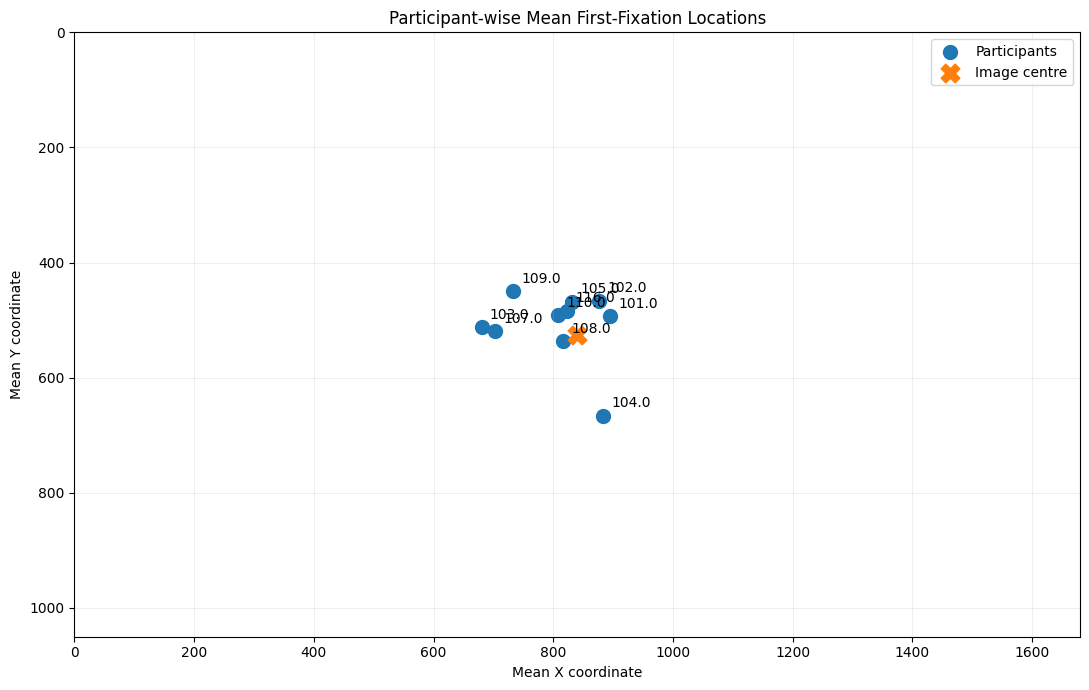

In [21]:
# Plot mean first-fixation locations by participant

plt.figure(figsize=(11, 7))

plt.scatter(
    participant_stats["mean_x"],
    participant_stats["mean_y"],
    s=100,
    label="Participants"
)

for _, row in participant_stats.iterrows():
    plt.annotate(
        str(row["subject"]),
        (row["mean_x"], row["mean_y"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

# Mark image centre
plt.scatter(
    840, 525,
    marker="X",
    s=180,
    label="Image centre"
)

plt.xlim(0, 1680)
plt.ylim(1050, 0)

plt.xlabel("Mean X coordinate")
plt.ylabel("Mean Y coordinate")
plt.title("Participant-wise Mean First-Fixation Locations")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "Figures", "participant_mean_locations.png"),
    dpi=300
)

plt.show()

### Participant-wise Analysis

Participant-level mean first-fixation locations showed variation
across the ten participants.

Some participants had mean fixation locations relatively close
to the image centre, while others showed shifts towards the left
or lower regions.

Participant 104 had the greatest mean distance from the image
centre (291.77 pixels), whereas participant 116 had the smallest
(186.52 pixels).

These differences suggest individual variation in first-fixation
behaviour. Further analysis is needed to determine whether
participants exhibit consistent spatial preferences.

### 19. Overall Spatial Distribution of Fixations

All post-centre fixation coordinates are combined to examine
which spatial regions receive the greatest concentration
of visual attention.

The initial centre fixation at index 0 is excluded.

In [22]:
# Extract all post-centre fixations

all_fixations = []

for record in records:
    for i in range(1, len(record["X"])):
        all_fixations.append({
            "image": record["name"],
            "subject": record["subject"],
            "split": record["split"],
            "x": record["X"][i],
            "y": record["Y"][i],
            "duration": record["T"][i]
        })

all_fixations_df = pd.DataFrame(all_fixations)

print("Total post-centre fixation observations:",
      len(all_fixations_df))

display(all_fixations_df.head())

Total post-centre fixation observations: 528476


,image,subject,split,x,y,duration
0,000000019544.jpg,101,train,827.3,362.3,226.0
1,000000019544.jpg,101,train,1451.9,416.5,217.0
2,000000019544.jpg,101,train,1193.3,265.4,302.0
3,000000019544.jpg,101,train,785.4,334.1,265.0
4,000000019544.jpg,101,train,500.2,394.1,204.0


### 20. Overall Fixation Density Heatmap

A two-dimensional histogram is generated using all post-centre
fixation coordinates.

This visualisation identifies spatial regions with high
concentrations of fixation observations across the dataset.

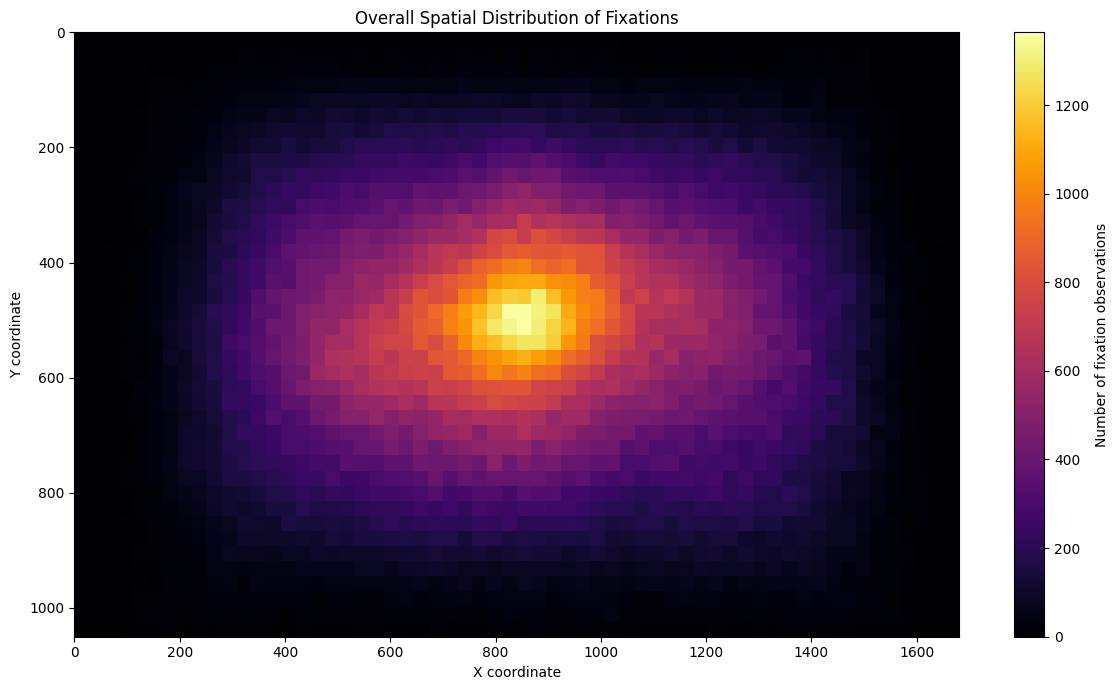

In [23]:
# Visualise all post-centre fixation locations

plt.figure(figsize=(12, 7))

plt.hist2d(
    all_fixations_df["x"],
    all_fixations_df["y"],
    bins=[60, 40],
    range=[[0, 1680], [0, 1050]],
    cmap="inferno"
)

plt.colorbar(label="Number of fixation observations")

plt.xlim(0, 1680)
plt.ylim(1050, 0)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Overall Spatial Distribution of Fixations")

plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "Figures", "overall_fixation_heatmap.png"),
    dpi=300
)

plt.show()

In [24]:
# Calculate overall fixation distribution

image_center_x = 840
image_center_y = 525

all_fixations_df["distance_from_center"] = np.sqrt(
    (all_fixations_df["x"] - image_center_x)**2 +
    (all_fixations_df["y"] - image_center_y)**2
)

print("Total fixation observations:", len(all_fixations_df))

print("\nMean fixation location:")
print("X:", round(all_fixations_df["x"].mean(), 2))
print("Y:", round(all_fixations_df["y"].mean(), 2))

print("\nMean distance from image centre:")
print(round(all_fixations_df["distance_from_center"].mean(), 2), "pixels")

print("\nMedian distance from image centre:")
print(round(all_fixations_df["distance_from_center"].median(), 2), "pixels")

Total fixation observations: 528476

Mean fixation location:
X: 856.14
Y: 520.19

Mean distance from image centre:
317.5 pixels

Median distance from image centre:
300.68 pixels


In [25]:
# Participant-wise overall fixation statistics

overall_participant_stats = (
    all_fixations_df
    .groupby("subject")
    .agg(
        total_fixations=("x", "count"),
        mean_x=("x", "mean"),
        mean_y=("y", "mean"),
        mean_distance=("distance_from_center", "mean"),
        median_distance=("distance_from_center", "median")
    )
    .round(2)
    .reset_index()
)

display(overall_participant_stats)

,subject,total_fixations,mean_x,mean_y,mean_distance,median_distance
0,101,50235,861.10,552.64,306.28,283.46
1,102,59619,897.42,459.85,257.51,232.42
2,103,52470,826.70,516.94,331.76,320.62
3,104,45750,875.63,615.71,308.51,291.02
4,105,52709,845.30,486.79,340.25,328.04
5,107,55755,824.50,533.51,315.44,299.76
6,108,52563,875.16,543.28,332.91,316.37
7,109,46211,849.08,522.96,364.61,358.10
8,110,54526,833.91,507.95,308.91,292.66
9,116,58638,870.08,487.97,320.90,306.11


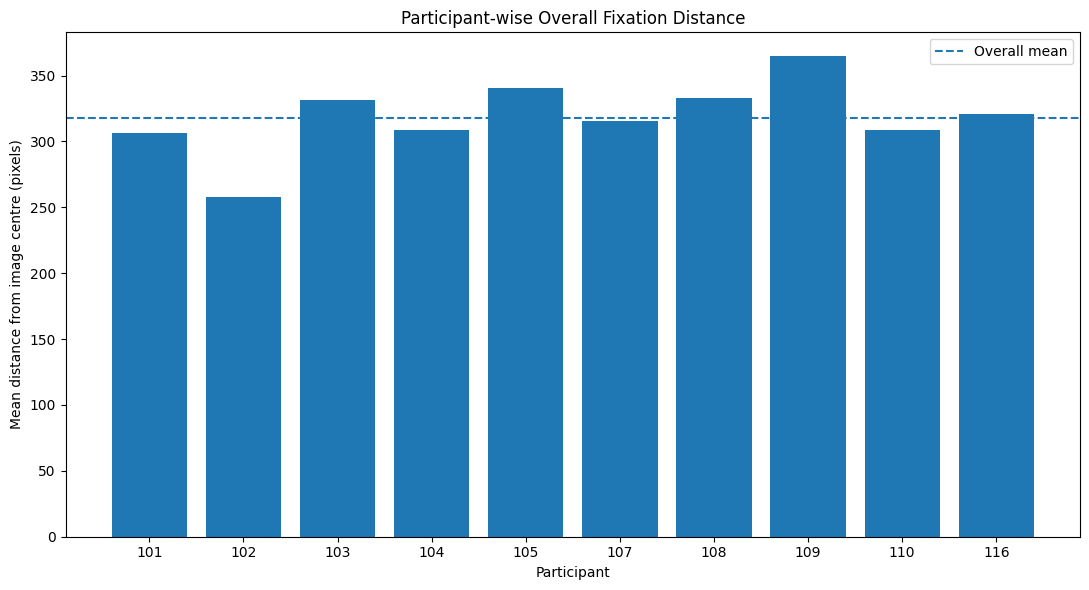

In [26]:
# Compare mean fixation distance across participants

plt.figure(figsize=(11, 6))

plt.bar(
    overall_participant_stats["subject"].astype(str),
    overall_participant_stats["mean_distance"]
)

plt.axhline(
    all_fixations_df["distance_from_center"].mean(),
    linestyle="--",
    label="Overall mean"
)

plt.xlabel("Participant")
plt.ylabel("Mean distance from image centre (pixels)")
plt.title("Participant-wise Overall Fixation Distance")

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "Figures", "participant_fixation_distance.png"),
    dpi=300
)

plt.show()

In [27]:
# Check image coverage across participants

images_per_subject = (
    all_fixations_df.groupby("subject")["image"]
    .nunique()
)

print("Unique images viewed by each participant:")
display(images_per_subject)

# Find images viewed by every participant

images_by_subject = [
    set(group["image"].unique())
    for _, group in all_fixations_df.groupby("subject")
]

common_images = set.intersection(*images_by_subject)

print("\nImages viewed by all participants:", len(common_images))
print("Total unique images:", all_fixations_df["image"].nunique())

Unique images viewed by each participant:


,image
subject,
101,3666
102,3669
103,3669
104,3656
105,3669
107,3669
108,3584
109,3666
110,3627



Images viewed by all participants: 3524
Total unique images: 3669


### 25. Comparing Participant Gaze Similarity

A shared set of 3,524 images viewed by all ten participants
is selected for comparison.

Each image is divided into a 12 × 8 spatial grid.
Fixation counts are calculated for each participant
within every grid region.

The resulting spatial distributions are normalised
and compared using cosine similarity.

This allows participant gaze patterns to be compared
under the same image conditions.

In [28]:
from itertools import combinations

# Select images viewed by all participants
subjects = sorted(all_fixations_df["subject"].unique())

common_data = all_fixations_df[
    all_fixations_df["image"].isin(common_images)
]

# Group fixation observations by image and participant
grouped = common_data.groupby(["image", "subject"])

# Create a spatial histogram for each image-participant pair
spatial_maps = {}

for (image, subject), group in grouped:

    hist, _, _ = np.histogram2d(
        group["x"],
        group["y"],
        bins=[12, 8],
        range=[[0, 1680], [0, 1050]]
    )

    spatial_maps[(image, subject)] = hist.flatten()

print("Spatial maps created:", len(spatial_maps))

Spatial maps created: 35240


In [29]:
# Calculate participant-wise gaze similarity

similarity_matrix = np.eye(len(subjects))

for i, subject_a in enumerate(subjects):
    for j in range(i + 1, len(subjects)):

        subject_b = subjects[j]
        image_similarities = []

        for image_name in common_images:

            map_a = spatial_maps[(image_name, subject_a)]
            map_b = spatial_maps[(image_name, subject_b)]

            norm_a = np.linalg.norm(map_a)
            norm_b = np.linalg.norm(map_b)

            if norm_a > 0 and norm_b > 0:

                similarity = np.dot(map_a, map_b) / (
                    norm_a * norm_b
                )

                image_similarities.append(similarity)

        mean_similarity = np.mean(image_similarities)

        similarity_matrix[i, j] = mean_similarity
        similarity_matrix[j, i] = mean_similarity

# Display similarity matrix

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=subjects,
    columns=subjects
)

print("Participant Gaze Similarity Matrix")
display(similarity_df.round(3))

Participant Gaze Similarity Matrix


,101,102,103,104,105,107,108,109,110,116
101,1.000,0.346,0.410,0.360,0.403,0.416,0.421,0.344,0.375,0.404
102,0.346,1.000,0.334,0.259,0.352,0.326,0.328,0.299,0.319,0.367
103,0.410,0.334,1.000,0.343,0.447,0.464,0.431,0.390,0.411,0.432
104,0.360,0.259,0.343,1.000,0.307,0.349,0.356,0.300,0.296,0.307
105,0.403,0.352,0.447,0.307,1.000,0.441,0.408,0.394,0.402,0.440
107,0.416,0.326,0.464,0.349,0.441,1.000,0.421,0.381,0.415,0.428
108,0.421,0.328,0.431,0.356,0.408,0.421,1.000,0.360,0.376,0.406
109,0.344,0.299,0.390,0.300,0.394,0.381,0.360,1.000,0.340,0.366
110,0.375,0.319,0.411,0.296,0.402,0.415,0.376,0.340,1.000,0.395
116,0.404,0.367,0.432,0.307,0.440,0.428,0.406,0.366,0.395,1.000


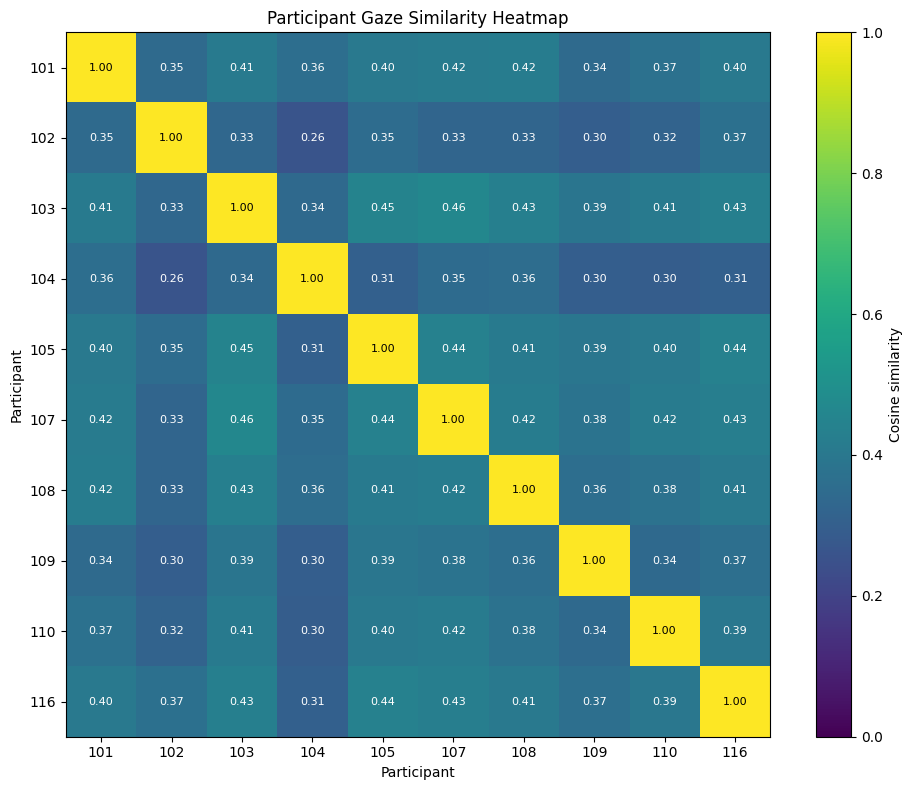

In [30]:
# Visualise participant gaze similarity

plt.figure(figsize=(10, 8))

plt.imshow(
    similarity_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Cosine similarity")

plt.xticks(range(len(subjects)), subjects)
plt.yticks(range(len(subjects)), subjects)

plt.xlabel("Participant")
plt.ylabel("Participant")
plt.title("Participant Gaze Similarity Heatmap")

# Display similarity values inside cells
for i in range(len(subjects)):
    for j in range(len(subjects)):
        plt.text(
            j, i,
            f"{similarity_matrix[i, j]:.2f}",
            ha="center",
            va="center",
            color="white" if similarity_matrix[i, j] < 0.65 else "black",
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "Figures", "gaze_similarity_heatmap.png"),
    dpi=300
)

plt.show()

In [31]:
# Count valid image comparisons for each participant pair

valid_image_counts = np.zeros(
    (len(subjects), len(subjects)),
    dtype=int
)

for i, subject_a in enumerate(subjects):
    for j, subject_b in enumerate(subjects):

        count = 0

        for image_name in common_images:
            map_a = spatial_maps[(image_name, subject_a)]
            map_b = spatial_maps[(image_name, subject_b)]

            if np.linalg.norm(map_a) > 0 and np.linalg.norm(map_b) > 0:
                count += 1

        valid_image_counts[i, j] = count

valid_counts_df = pd.DataFrame(
    valid_image_counts,
    index=subjects,
    columns=subjects
)

display(valid_counts_df)

,101,102,103,104,105,107,108,109,110,116
101,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
102,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
103,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
104,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
105,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
107,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
108,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
109,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
110,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524
116,3524,3524,3524,3524,3524,3524,3524,3524,3524,3524


### Participant Gaze Similarity Analysis

Gaze similarity was evaluated using 3,524 images viewed by
all ten participants.

Each image was divided into a 12 × 8 spatial grid.
Fixation distributions were compared using cosine similarity.

All participant pairs had 3,524 valid image comparisons.

The highest off-diagonal similarity was 0.464
(between participants 103 and 107).

The lowest was 0.259
(between participants 102 and 104).

The results indicate partial spatial overlap between
participants, alongside individual differences in
their fixation distributions.

These findings describe similarity at the resolution
of the selected spatial grid and do not establish
agreement at individual pixel locations.

In [32]:
# Calculate overall participant similarity

upper_triangle = similarity_matrix[
    np.triu_indices(len(subjects), k=1)
]

print("Number of participant pairs:", len(upper_triangle))

print("Mean pairwise similarity:",
      round(np.mean(upper_triangle), 4))

print("Median pairwise similarity:",
      round(np.median(upper_triangle), 4))

print("Minimum similarity:",
      round(np.min(upper_triangle), 4))

print("Maximum similarity:",
      round(np.max(upper_triangle), 4))

Number of participant pairs: 45
Mean pairwise similarity: 0.3749
Median pairwise similarity: 0.376
Minimum similarity: 0.2587
Maximum similarity: 0.4638


### Overall Participant Similarity

Across 45 unique participant pairs, the mean cosine similarity
was 0.3749, with a median of 0.3760.

Similarity scores ranged from 0.2587 to 0.4638.

These results indicate partial overlap in spatial fixation
distributions, alongside variation between participants.

All pairwise comparisons used 3,524 shared images.

In [33]:
# Analyse post-centre fixation durations

duration = all_fixations_df["duration"]

print("Total observations:", len(duration))

print("\nFixation duration statistics (milliseconds)")
print("Minimum:", duration.min())
print("Mean:", round(duration.mean(), 2))
print("Median:", duration.median())
print("95th percentile:", round(duration.quantile(0.95), 2))
print("99th percentile:", round(duration.quantile(0.99), 2))
print("Maximum:", duration.max())

print("\nFixations longer than 1000 ms:", (duration > 1000).sum())
print("Fixations longer than 5000 ms:", (duration > 5000).sum())

Total observations: 528476

Fixation duration statistics (milliseconds)
Minimum: 2.0
Mean: 262.04
Median: 230.0
95th percentile: 525.0
99th percentile: 862.0
Maximum: 5006.0

Fixations longer than 1000 ms: 3366
Fixations longer than 5000 ms: 1


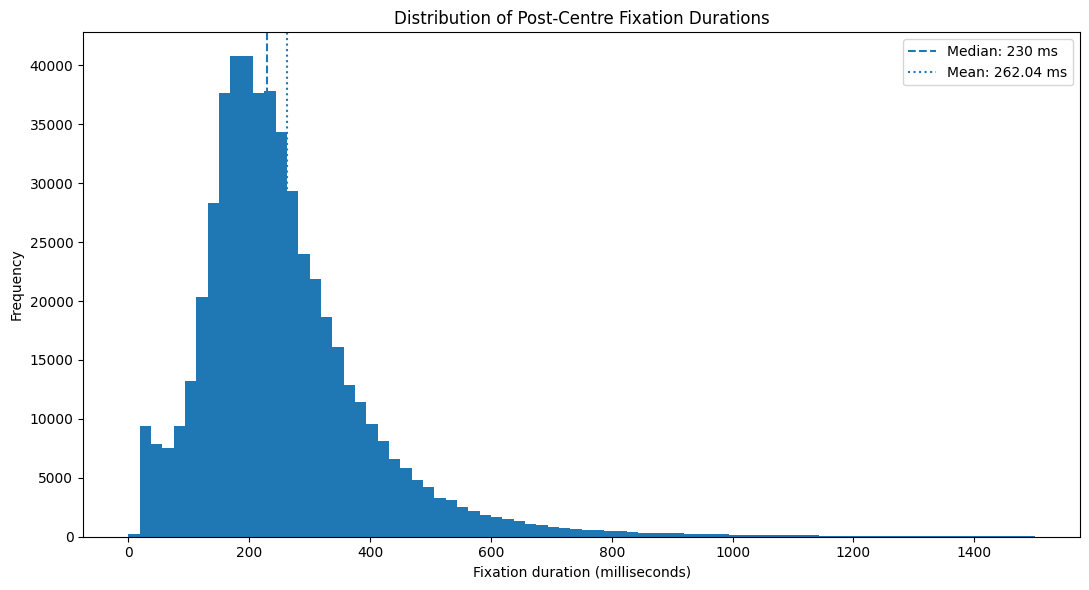

Observations above 1500 ms: 1101


In [34]:
# Visualise fixation duration distribution

plt.figure(figsize=(11, 6))

plt.hist(
    duration,
    bins=80,
    range=(0, 1500)
)

plt.axvline(
    duration.median(),
    linestyle="--",
    label="Median: 230 ms"
)

plt.axvline(
    duration.mean(),
    linestyle=":",
    label="Mean: 262.04 ms"
)

plt.xlabel("Fixation duration (milliseconds)")
plt.ylabel("Frequency")
plt.title("Distribution of Post-Centre Fixation Durations")

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "Figures", "fixation_duration_distribution.png"),
    dpi=300
)

plt.show()

print("Observations above 1500 ms:", (duration > 1500).sum())

### Fixation Duration Analysis

The distribution of post-centre fixation durations was
right-skewed, with most observations concentrated
between approximately 150 and 300 milliseconds.

The median duration was 230 ms, while the mean was
262.04 ms.

The 95th percentile was 525 ms and the 99th percentile
was 862 ms.

A total of 1,101 observations exceeded 1,500 ms,
representing approximately 0.21% of all observations.

These results indicate that fixation durations varied
considerably, with a relatively small number of
long-duration observations.

## 31. Exporting Research Results

This section exports the main analytical results into CSV files
for future reporting, visualisation and reproducibility.

In [35]:

# Create Results folder
results_folder = os.path.join(project_path, "Results")
os.makedirs(results_folder, exist_ok=True)

# 1. First fixation data
first_fixations_df.to_csv(
    os.path.join(results_folder, "first_fixations.csv"),
    index=False
)

# 2. First fixation statistics by participant
first_stats = first_fixations_df.copy()

first_stats["distance_from_center"] = np.sqrt(
    (first_stats["first_x"] - 840)**2 +
    (first_stats["first_y"] - 525)**2
)

first_participant_summary = first_stats.groupby("subject").agg(
    trials=("image", "count"),
    mean_x=("first_x", "mean"),
    mean_y=("first_y", "mean"),
    mean_distance=("distance_from_center", "mean"),
    median_distance=("distance_from_center", "median")
).reset_index()

first_participant_summary.to_csv(
    os.path.join(results_folder, "first_fixation_statistics.csv"),
    index=False
)

# 3. Overall fixation statistics by participant
overall_participant_stats.to_csv(
    os.path.join(results_folder, "overall_fixation_statistics.csv"),
    index=False
)

# 4. Gaze similarity matrix
similarity_df.to_csv(
    os.path.join(results_folder, "gaze_similarity_matrix.csv")
)

# 5. Valid image comparison counts
valid_counts_df.to_csv(
    os.path.join(results_folder, "valid_image_comparison_counts.csv")
)

# 6. Fixation duration statistics
duration_summary = duration.describe().to_frame(
    name="duration_ms"
)

duration_summary.to_csv(
    os.path.join(results_folder, "fixation_duration_statistics.csv")
)

# Display saved files
print("Research results exported successfully!\n")

for filename in sorted(os.listdir(results_folder)):
    print(filename)


Research results exported successfully!

first_fixation_statistics.csv
first_fixations.csv
fixation_duration_statistics.csv
gaze_similarity_matrix.csv
overall_fixation_statistics.csv
valid_image_comparison_counts.csv


## 32. Research Figure Inventory

This section verifies the visual outputs generated
during the exploratory data analysis.

In [36]:

# Check all saved research figures

figures_folder = os.path.join(project_path, "Figures")
os.makedirs(figures_folder, exist_ok=True)

figure_files = sorted(os.listdir(figures_folder))

print("Total saved figures:", len(figure_files))
print("\nSaved figure files:")

for filename in figure_files:
    print(filename)


Total saved figures: 6

Saved figure files:
first_fixation_heatmap.png
fixation_duration_distribution.png
gaze_similarity_heatmap.png
overall_fixation_heatmap.png
participant_fixation_distance.png
participant_mean_locations.png


## 33. Project Summary

**Project Title:** Understanding Human Visual Attention Through Gaze Trajectories in Natural Images

**Dataset:** COCO-FreeView

**Research Type:** Exploratory Data Analysis

**Participants:** 10

**Training Records:** 30,129

**Validation Records:** 6,457

**Total Trials:** 36,586

**Shared Images:** 3,524

**Programming Language:** Python

**Environment:** Google Colab

**Libraries:** Pandas, NumPy, Matplotlib

### Research Objectives

1. Analyse the location of first post-centre fixations.
2. Identify spatial regions with high fixation concentrations.
3. Compare gaze distributions across participants.
4. Examine fixation duration patterns.

In [37]:
print("Project folder:", project_path)
print("Dataset files:", os.listdir(dataset_folder))
print("Result files:", len(os.listdir(results_folder)))
print("Figure files:", len(os.listdir(figures_folder)))

Project folder: /content/drive/MyDrive/COCO-FreeView-Research
Dataset files: ['COCOFreeView_fixations_train.json', 'COCOFreeView_fixations_validation.json']
Result files: 6
Figure files: 6


### Centre-Fixation Verification

The first coordinate in each trial was examined to verify the initial centre-fixation assumption.

- Mean initial X-coordinate: 838.31 pixels
- Mean initial Y-coordinate: 520.13 pixels
- Image centre: (840, 525)
- Mean distance from image centre: 31.27 pixels

The close proximity of the mean initial coordinates to the image centre supports treating index 0 as the initial centre fixation. Therefore, index 1 was used to extract the first post-centre fixation.

In [38]:
centre_x = np.array([record["X"][0] for record in records if len(record["X"]) > 0])
centre_y = np.array([record["Y"][0] for record in records if len(record["Y"]) > 0])

print("Mean initial X:", centre_x.mean())
print("Mean initial Y:", centre_y.mean())
print("Image centre: (840, 525)")
print("Mean distance from centre:", np.sqrt(
    (centre_x - 840)**2 + (centre_y - 525)**2
).mean())

Mean initial X: 838.3114907341605
Mean initial Y: 520.1333925545291
Image centre: (840, 525)
Mean distance from centre: 31.270323182920762
